# 09 — Forecasting availability, and demand with real weather forecasts

**Does:** forecasts tomorrow's solar, wind and hydro availability for every state in two ways: the Stage 2 physical rules run on **real day-ahead weather forecasts**, and a **statistical ladder** that uses only what is known today. It also re-runs the Stage 3 demand models with the real forecasts, giving a realistic case between "perfect weather" and "persistence weather".

**Question:** how well can tomorrow's renewable supply be forecast, and how much do real weather forecasts help supply and demand?

**Input:** day-ahead weather forecasts (Open-Meteo previous-runs archive, downloaded here and cached in `data/cache/forecast_hourly/`), `availability_daily.csv`, `weather_state_daily.csv`, Stage 3 inputs

**Output:** `data/raw/forecast_weather_daily.csv`, `data/processed/forecast_weather_state_daily.csv`, `data/processed/availability_forecast_test.csv`, `data/processed/demand_forecast_dayahead.csv`

**Code:** `src/weather.py` (forecast download), `src/availability.py` (`forecast_availability`), `src/features.py`, `src/forecast.py`

**Logged in:** `docs/model_log.md`, Step 17

## Design (Stage 4 decisions)

| Choice | Value |
|---|---|
| Approach | **Both:** physical rules on real forecasts, and a statistical ladder; compared, plus their average |
| Forecasts | **True day-ahead forecasts** (`*_previous_day1`: each hour as forecast the day before). Complete from March 2024, so **every case is scored on Mar 2024 – Mar 2025 (13 months)** |
| Ladder | Solar and wind: L0 today → L1 monthly profile → L4 LightGBM (today's factor, 3- and 7-day averages, season, today's weather). Hydro: bucket rolled forward one day |
| Scoring | Error in **available MW** summed over India per fuel; target skill ≥ 0.20 vs persistence for solar and wind |
| Levels | Each state's scale from the actual-weather fit (Stage 2) is **frozen** and applied to forecasts, never re-fitted |
| Demand | Models trained on actual weather (as in Stage 3), fed the day-ahead forecasts at test time ("perfect-prog": forecasts exist only for the test period) |
| **Anchoring** (decided after the first run, section 2b) | Tomorrow = **today's actual + (forecast for tomorrow − forecast for today)**: for solar and wind availability and for demand temperatures. Cancels the forecast model's seasonal bias. Raw forecasts are kept for comparison |

**One change from the plan:** "L5 = LightGBM + forecast weather" is not built separately. Trained on actual weather, it would only re-learn the Stage 2 rule, because actual availability *is* that rule applied to actual weather, so it would equal "physics on forecasts". Instead the two approaches are also **averaged**, a standard forecast combination that needs no training.

**What the weather cases mean for supply:** *perfect* weather gives zero error by construction (availability is defined from weather); *persistence* weather = today's availability for solar and wind, and the bucket rolled forward with today's inflow for hydro; *day-ahead* = the real forecast.

In [1]:
import sys
sys.path.append("../src")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import weather as w
import availability as av
import features as F
import forecast as fc
from dispatch import load_demand, load_generators, PROCESSED

SCORE = slice("2024-03-01", "2025-03-31")            # all cases compared over these 13 months
points = w.load_points()
gen = load_generators()
cap = gen.groupby(["State", "Fuel_Type"])["Capacity_MW"].sum()
actual_sw = pd.read_csv(PROCESSED / "weather_state_daily.csv", parse_dates=["Date"])
actual_avail = pd.read_csv(PROCESSED / "availability_daily.csv", parse_dates=["Date"])

## 1. Day-ahead weather forecasts

In [2]:
hourly = w.fetch_all_previous_runs(points, verbose=False)
fc_daily = w.hourly_to_daily(hourly)
assert len(fc_daily) == len(points) * 456 and fc_daily.Point_ID.nunique() == len(points)

complete = fc_daily.notna().all(axis=1).groupby(fc_daily.Date.dt.to_period("M")).mean()
print("share of point-days with a full forecast, by month:")
print(complete.round(2).to_string())
assert (complete.loc["2024-03":] > 0.99).all()

fc_daily.to_csv(w.RAW / "forecast_weather_daily.csv", index=False, float_format="%.2f")
fc_state = w.combine_points(fc_daily.dropna(), points, w.load_population())
fc_state.to_csv(PROCESSED / "forecast_weather_state_daily.csv", index=False, float_format="%.2f")
print(f"saved {len(fc_daily):,} point-days and {len(fc_state):,} state-days")

share of point-days with a full forecast, by month:
Date
2024-01    0.00
2024-02    0.45
2024-03    1.00
2024-04    1.00
2024-05    1.00
2024-06    1.00
2024-07    1.00
2024-08    1.00
2024-09    1.00
2024-10    1.00
2024-11    1.00
2024-12    1.00
2025-01    1.00
2025-02    1.00
2025-03    1.00
Freq: M


saved 68,856 point-days and 41,309 state-days


### How good are the forecasts? (vs the archive we treat as actual, Mar 2024 – Mar 2025)

In [3]:
act = pd.read_csv(w.RAW / "weather_daily.csv", parse_dates=["Date"])
both = fc_daily.merge(act, on=["Point_ID", "Date"], suffixes=("_fc", "_act"))
both = both[both.Date.between(SCORE.start, SCORE.stop)].dropna()
quality = pd.DataFrame({v: {"correlation": both[f"{v}_fc"].corr(both[f"{v}_act"]),
                             "mean abs error": (both[f"{v}_fc"] - both[f"{v}_act"]).abs().mean(),
                             "forecast ÷ actual (average)": both[f"{v}_fc"].mean() / both[f"{v}_act"].mean()}
                        for v in w.DAILY_VARIABLES}).T
quality.round(3)

,correlation,mean abs error,forecast ÷ actual (average)
temperature_2m_max,0.969,1.157,1.002
temperature_2m_mean,0.981,0.941,1.019
temperature_2m_min,0.962,1.457,1.050
precipitation_sum,0.589,3.232,0.801
shortwave_radiation_sum,0.839,2.194,0.996
cloud_cover_mean,0.868,14.104,1.150
wind_speed_100m_mean,0.903,2.478,0.955


## 2. Availability from the forecasts

Wind: the power curve on each forecast hour, as in Stage 2. Solar and hydro: the Stage 2 rules on the forecast daily weather. Each state's scale is the one fitted on actual weather.

In [4]:
wind_pts = points[points.Purpose == "wind"]
actual_wind = av.daily_wind_output(w.fetch_all_hourly(wind_pts, verbose=False), points)
_, scales = av.build_availability(actual_sw, actual_wind, gen, return_scales=True)   # frozen levels

fc_wind_hourly = hourly[hourly.Point_ID.isin(wind_pts.Point_ID)][["Point_ID", "Time", "wind_speed_100m"]].dropna()
fc_wind = av.daily_wind_output(fc_wind_hourly, points)

raw = av.forecast_availability(actual_sw, fc_state, fc_wind, gen, scales)
cases = {
    "perfect": actual_avail,
    "day-ahead raw": raw,
    "day-ahead": av.anchor_availability(raw, actual_avail),   # solar, wind anchored; hydro = rolled bucket
    "persistence": av.forecast_availability(actual_sw, actual_sw.assign(Date=actual_sw.Date + pd.Timedelta(days=1)),
        actual_wind.rename(index=lambda d: d + pd.Timedelta(days=1), level="Date"), gen, scales),
}
check = cases["persistence"].merge(actual_avail.assign(Date=actual_avail.Date + pd.Timedelta(days=1)),
                                   on=["Date", "State", "Fuel_Type"])
same = check[check.Fuel_Type.isin(["Solar", "Wind"])]
assert np.allclose(same.Factor_x, same.Factor_y, atol=1e-4), "persistence solar/wind should equal today's factor"   # saved file has 4 decimals
{k: len(v[v.Date.between(SCORE.start, SCORE.stop)]) for k, v in cases.items()}

{'perfect': 36828,
 'day-ahead raw': 36828,
 'day-ahead': 36828,
 'persistence': 36828}

### 2b. Why anchoring: the raw forecasts are biased by season

The first run scored raw forecasts and found solar availability *worse* than "same as today". The reason is a seasonal bias in the forecast model: compare India's forecast and actual available MW by month.

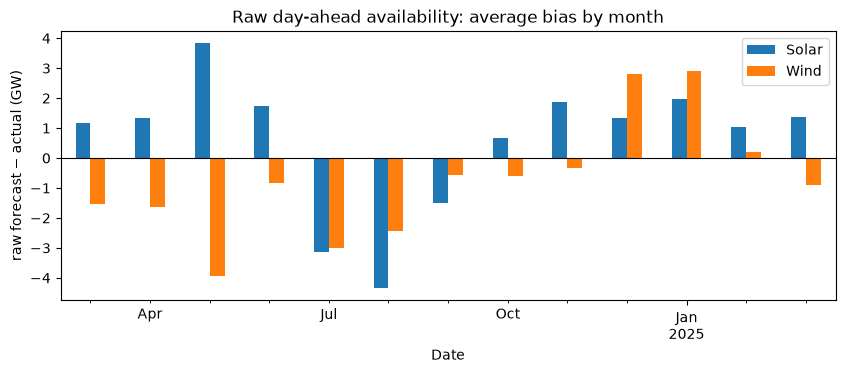

Date,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03
Solar,1.2,1.3,3.8,1.7,-3.1,-4.3,-1.5,0.7,1.9,1.3,2.0,1.0,1.4
Wind,-1.5,-1.6,-4.0,-0.8,-3.0,-2.4,-0.6,-0.6,-0.3,2.8,2.9,0.2,-0.9


In [5]:
def india_mw(t, fuel):
    t = t[t.Fuel_Type == fuel].join(cap.rename("C"), on=["State", "Fuel_Type"])
    return (t.Factor * t.C).groupby(t.Date).sum()

bias = pd.DataFrame({fuel: (india_mw(raw, fuel) - india_mw(actual_avail, fuel)).dropna().loc[SCORE.start:]
                     for fuel in ["Solar", "Wind"]})
monthly_bias = bias.groupby(bias.index.to_period("M")).mean() / 1000
monthly_bias.plot.bar(figsize=(10, 3.5)); plt.axhline(0, color="black", lw=0.8)
plt.ylabel("raw forecast − actual (GW)"); plt.title("Raw day-ahead availability: average bias by month"); plt.show()
monthly_bias.round(1).T

The forecast model is **too sunny in the dry, hazy months** (up to +3.8 GW of solar in May) and **too cloudy in the monsoon** (down to −4.3 GW in August); wind is too low most of the year. The bias is about the same on consecutive days, while "same as today" has none. Taking only the forecast *change* and adding it to today's actual cancels it: that is the anchored forecast. Both forecasts it uses are known on day D (the forecast for D was issued on D − 1).

## 3. Statistical ladder for solar and wind (no weather forecast)

In [6]:
ladder_preds = []
for fuel in ["Solar", "Wind"]:
    f = F.build_availability_features(actual_avail, actual_sw, fuel)
    for name, make in [("L1 month profile", fc.MonthProfile), ("L4 LightGBM", lambda: fc.Trees(fc.AVAIL_FEATURES[fuel]))]:
        t = time.time()
        p = fc.walk_forward(f, make, start=SCORE.start, to_forecast=fc.factor_from_prediction)
        ladder_preds.append(p[["Date", "State", "Fuel_Type", "Forecast"]].assign(Model=name, Weather="none"))
        print(f"{fuel:5s} {name:18s} {time.time() - t:5.1f} s")

Solar L1 month profile     0.1 s


Solar L4 LightGBM         51.5 s
Wind  L1 month profile     0.0 s


Wind  L4 LightGBM         43.7 s


## 4. Scores (Mar 2024 – Mar 2025)

In [7]:
rows = []
for weather, table in cases.items():
    model = {"perfect": "physics, perfect weather", "persistence": "L0 persistence",
             "day-ahead raw": "physics, day-ahead raw", "day-ahead": "physics, day-ahead anchored"}[weather]
    rows.append(table.rename(columns={"Factor": "Forecast"}).assign(Model=model, Weather=weather))
preds = pd.concat(rows + ladder_preds, ignore_index=True)

# combination: average of anchored physics and LightGBM
phys = preds[preds.Model == "physics, day-ahead anchored"].set_index(["Date", "State", "Fuel_Type"]).Forecast
lgb = preds[preds.Model == "L4 LightGBM"].set_index(["Date", "State", "Fuel_Type"]).Forecast
comb = ((phys + lgb) / 2).dropna().rename("Forecast").reset_index().assign(Model="average of anchored physics + L4", Weather="day-ahead")
preds = pd.concat([preds, comb], ignore_index=True)
preds = preds.merge(actual_avail.rename(columns={"Factor": "Actual"}), on=["Date", "State", "Fuel_Type"])
preds = preds.join(cap.rename("Capacity_MW"), on=["State", "Fuel_Type"])
scored = preds[preds.Date.between(SCORE.start, SCORE.stop)]

def mw_error(p):
    g = p.assign(A=p.Actual * p.Capacity_MW, F=p.Forecast * p.Capacity_MW).groupby("Date")[["A", "F"]].sum()
    return (g.A - g.F).abs().mean()

rows = []
for fuel in av.WEATHER_FUELS + ["all"]:
    sub = scored if fuel == "all" else scored[scored.Fuel_Type == fuel]
    base = mw_error(sub[sub.Model == "L0 persistence"])
    for model, p in sub.groupby("Model"):
        if fuel == "all" and p.Fuel_Type.nunique() < 4:
            continue                                   # the ladder covers solar and wind only
        mae = mw_error(p)
        rows.append({"Fuel": fuel, "Model": model, "national MAE (MW)": mae, "skill": 1 - mae / base})
res = pd.DataFrame(rows).set_index(["Fuel", "Model"])
res.round({"national MAE (MW)": 0, "skill": 3})

national MAE (MW)  skill
Fuel        Model                                                     
Solar       L0 persistence                               1375.0  0.000
            L1 month profile                             2110.0 -0.535
            L4 LightGBM                                  1276.0  0.072
            average of anchored physics + L4              921.0  0.330
            physics, day-ahead anchored                  1155.0  0.160
            physics, day-ahead raw                       2171.0 -0.579
            physics, perfect weather                        0.0  1.000
Wind        L0 persistence                               3203.0  0.000
            L1 month profile                             5877.0 -0.835
            L4 LightGBM                                  3175.0  0.009
            average of anchored physics + L4             1919.0  0.401
            physics, day-ahead anchored                  1647.0  0.486
            physics, day-ahead raw                       2326.0  0.274
            physics, perfect weather                        0.0  1.000
Large Hydro L0 persistence                                 89.0  0.000
            physics, day-ahead anchored                    64.0  0.277
            physics, day-ahead raw                         64.0  0.277
            physics, perfect weather                        0.0  1.000
Small Hydro L0 persistence                                 39.0  0.000
            physics, day-ahead anchored                    27.0  0.316
            physics, day-ahead raw                         27.0  0.316
            physics, perfect weather                        0.0  1.000
all         L0 persistence                               3489.0  0.000
            physics, day-ahead anchored                  2101.0  0.398
            physics, day-ahead raw                       3059.0  0.123
            physics, perfect weather                        0.0  1.000

Note: the "all" rows add the fuels' MW before taking the error, so solar, wind and hydro errors that cancel on a day partly offset. The statistical ladder covers solar and wind only, so it has no "all" or hydro rows.

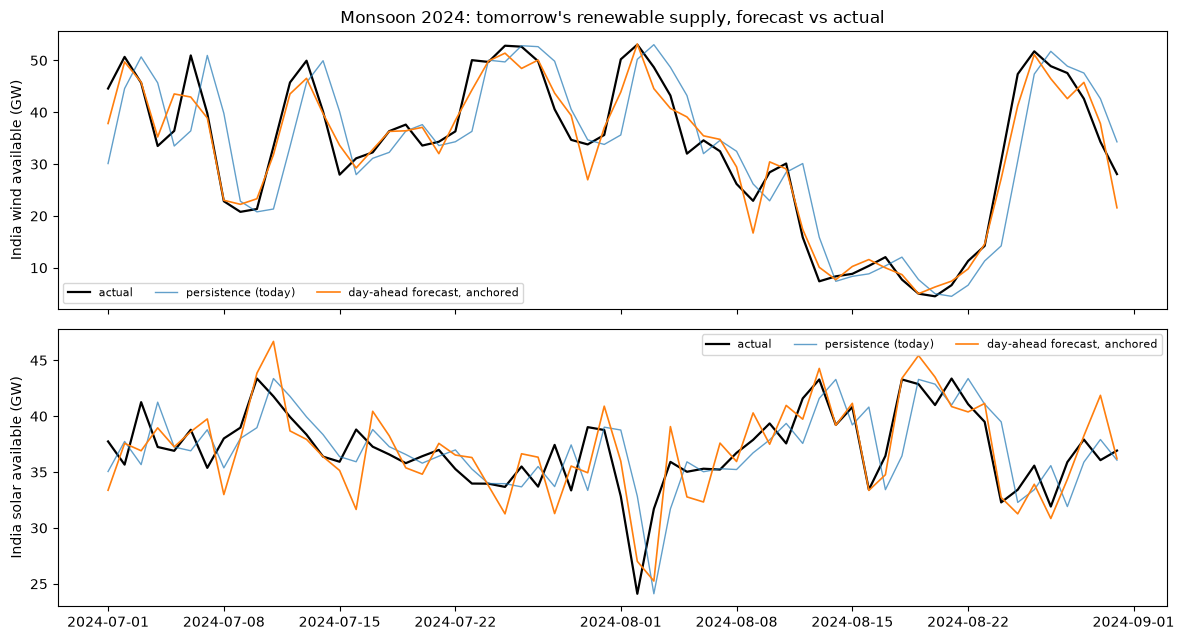

In [8]:
def mw_by_date(p):
    return p.assign(A=p.Actual * p.Capacity_MW, F=p.Forecast * p.Capacity_MW).groupby("Date")[["A", "F"]].sum() / 1000

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
window = slice("2024-07-01", "2024-08-31")
for ax, fuel in zip(axes, ["Wind", "Solar"]):
    sub = scored[scored.Fuel_Type == fuel]
    a = mw_by_date(sub[sub.Model == "L0 persistence"]).loc[window]
    ax.plot(a.A, color="black", lw=1.6, label="actual")
    ax.plot(a.F, lw=1, alpha=0.7, label="persistence (today)")
    ax.plot(mw_by_date(sub[sub.Model == "physics, day-ahead anchored"]).loc[window].F, lw=1.2, label="day-ahead forecast, anchored")
    ax.set_ylabel(f"India {fuel.lower()} available (GW)"); ax.legend(ncol=3, fontsize=8)
axes[0].set_title("Monsoon 2024: tomorrow's renewable supply, forecast vs actual")
plt.tight_layout(); plt.show()

In [9]:
by_state = (scored[scored.Fuel_Type == "Wind"]
            .assign(e=lambda d: (d.Actual - d.Forecast).abs() * d.Capacity_MW)
            .groupby(["State", "Model"]).e.mean().unstack() / 1000)
by_state["skill (anchored)"] = 1 - by_state["physics, day-ahead anchored"] / by_state["L0 persistence"]
by_state[["L0 persistence", "physics, day-ahead anchored", "skill (anchored)"]].sort_values(
    "L0 persistence", ascending=False).round(3).rename(columns=lambda c: c if "skill" in c else c + " (GW)")

Model,L0 persistence (GW),"physics, day-ahead anchored (GW)",skill (anchored)
State,,,
Gujarat,1.561,0.999,0.360
Tamil Nadu,0.874,0.660,0.245
SR Karnataka,0.619,0.426,0.312
Rajasthan,0.578,0.350,0.395
WR Maharashtra,0.551,0.361,0.345
MP,0.441,0.352,0.201
Andhra Pradesh,0.379,0.310,0.183
Telangana,0.014,0.011,0.175
Kerala,0.006,0.005,0.197


## 5. Demand with real day-ahead weather forecasts

In [10]:
demand = load_demand()
hol, pad = F.load_holidays(), F.load_paddy()
f_perfect = F.build_features(demand, actual_sw, hol, pad, "perfect")
f_raw = F.build_features(demand, actual_sw, hol, pad, "day-ahead", forecast_weather=fc_state)
f_anch = F.build_features(demand, actual_sw, hol, pad, "day-ahead",
                          forecast_weather=w.anchor_forecast(actual_sw, fc_state))   # temperatures anchored
print(f"day-ahead feature rows: {len(f_anch):,} from {f_anch.Date.min().date()}")

L = fc.FEATURE_SETS
models = {"L3 linear + weather": lambda: fc.Linear(L["L3"]), "L4 LightGBM": lambda: fc.Trees(L["L4"]),
          "L6 LightGBM median": lambda: fc.Trees(L["L4"], quantile=0.5)}
dayahead = []
for name, make in models.items():
    for label, test_f in [("day-ahead raw", f_raw), ("day-ahead", f_anch)]:
        t = time.time()
        p = fc.walk_forward(f_perfect, make, start=SCORE.start, test_f=test_f)
        dayahead.append(p[["Date", "State", "Forecast", "Actual"]].assign(Model=name, Weather=label))
        print(f"{name:22s} {label:14s} {time.time() - t:5.1f} s")
dayahead = pd.concat(dayahead, ignore_index=True)

stage3 = pd.read_csv(PROCESSED / "demand_forecast_test.csv", parse_dates=["Date"])
stage3 = stage3[stage3.State != "National"]
allcases = pd.concat([stage3[stage3.Model.isin(list(models) + ["L0 persistence"])], dayahead])
allcases = allcases[allcases.Date.between(SCORE.start, SCORE.stop)]

def nat_mae(p):
    g = p.groupby("Date")[["Actual", "Forecast"]].sum()
    return (g.Actual - g.Forecast).abs().mean()

base = nat_mae(allcases[allcases.Model == "L0 persistence"])
d = allcases[allcases.Model != "L0 persistence"].groupby(["Model", "Weather"]).apply(nat_mae).unstack()
d = d[["perfect", "day-ahead", "day-ahead raw", "persistence"]]
pd.concat({"national MAE (MW)": d.round(0), "skill": (1 - d / base).round(3)}, axis=1)

day-ahead feature rows: 13,056 from 2024-02-18


L3 linear + weather    day-ahead raw    0.6 s


L3 linear + weather    day-ahead        0.5 s


L4 LightGBM            day-ahead raw   56.2 s


L4 LightGBM            day-ahead       54.9 s


L6 LightGBM median     day-ahead raw   59.4 s


L6 LightGBM median     day-ahead       59.4 s


national MAE (MW)                                      \
Weather                       perfect day-ahead day-ahead raw persistence   
Model                                                                       
L3 linear + weather            3017.0    3090.0        3376.0      3274.0   
L4 LightGBM                    2688.0    2753.0        3046.0      2965.0   
L6 LightGBM median             2543.0    2623.0        2853.0      2874.0   

                      skill                                      
Weather             perfect day-ahead day-ahead raw persistence  
Model                                                            
L3 linear + weather   0.403     0.388         0.332       0.352  
L4 LightGBM           0.468     0.455         0.397       0.413  
L6 LightGBM median    0.497     0.481         0.435       0.431

### The best day-ahead forecast per fuel (for Stage 5)

Chosen by national MW error over the scored months: solar = average of anchored physics and LightGBM; wind = anchored physics; hydro = the rolled bucket with forecast rain.

In [11]:
BEST = {"Solar": "average of anchored physics + L4", "Wind": "physics, day-ahead anchored",
        "Large Hydro": "physics, day-ahead anchored", "Small Hydro": "physics, day-ahead anchored"}
best = pd.concat([preds[(preds.Fuel_Type == fuel) & (preds.Model == model)] for fuel, model in BEST.items()])
best = best.assign(Model="best day-ahead", Weather="day-ahead")
preds = pd.concat([preds, best], ignore_index=True)
b = best[best.Date.between(SCORE.start, SCORE.stop)]
base_all = mw_error(scored[scored.Model == "L0 persistence"])
print(f"all renewables, best day-ahead: national MAE {mw_error(b):,.0f} MW, skill {1 - mw_error(b) / base_all:.3f}")

all renewables, best day-ahead: national MAE 1,937 MW, skill 0.445


## 6. Save

In [12]:
out = preds.loc[preds.Date >= fc.TEST_START, ["Date", "State", "Fuel_Type", "Model", "Weather", "Forecast", "Actual"]]
out.to_csv(PROCESSED / "availability_forecast_test.csv", index=False, float_format="%.4f")
dayahead[["Date", "State", "Model", "Weather", "Forecast", "Actual"]].to_csv(
    PROCESSED / "demand_forecast_dayahead.csv", index=False, float_format="%.1f")
print(f"saved {len(out):,} availability rows and {len(dayahead):,} demand rows")

saved 247,196 availability rows and 76,032 demand rows


## Conclusions

**Raw day-ahead weather forecasts are biased by season**, and that bias, not random error, decided the first run: solar availability from raw forecasts was *worse* than "same as today" (skill −0.58), and demand with raw forecasts was no better than with today's weather. The forecast model is too sunny in the hazy dry months (up to +3.8 GW of solar in May), too cloudy in the monsoon (−4.3 GW in August) and too calm for wind most of the year. **Anchoring** (today's actual + the forecast *change*) cancels the bias, because it is about the same on consecutive days.

**Availability (national available-MW error, Mar 2024 – Mar 2025; skill vs "same as today"):**

| Fuel | Same as today | Best day-ahead | Skill | Best method |
|---|---|---|---|---|
| Solar | 1,375 MW | 921 MW | **0.33** ✅ | average of anchored physics and LightGBM |
| Wind | 3,203 MW | 1,647 MW | **0.49** ✅ | anchored physics |
| Large hydro | 89 MW | 64 MW | 0.28 | bucket rolled forward with forecast rain |
| Small hydro | 39 MW | 27 MW | 0.32 | same |

- **Without a weather forecast, renewable output is close to unpredictable** beyond "same as today": the best statistical model gains 7% for solar and 1% for wind; a monthly average is far worse than persistence (−54%, −84%). Tomorrow's sun and wind are weather, not habit
- **Wind is the biggest supply uncertainty:** even forecast well, its typical national error (1.6 GW) is two-thirds of the demand error (2.6 GW). Gujarat has the largest wind error (1.0 GW anchored, 1.6 GW persistence); Rajasthan gains most from the forecast (skill 0.40 for wind)
- **Solar benefits from combining:** anchored physics alone gains 16%, LightGBM alone 7%, their average 33%: their errors are different, so they partly cancel
- **Hydro is easy:** reservoirs change slowly; errors are tens of MW

**Demand with real day-ahead forecasts (anchored):** L6 national MAE **2,623 MW, skill 0.48**, close to perfect weather (0.50) and better than today's weather (0.43). Raw forecasts would have given 0.44, no better than no forecast. **0.48 is the realistic headline for Stage 3**, replacing the 0.44–0.50 range.

**Weather-forecast quality (vs the archive):** temperature typically within ~1 °C (correlation 0.97–0.98), wind 0.90, solar radiation 0.84, cloud 0.87, rain only 0.59 (and 20% too little).

**For Stage 5:** "best day-ahead" availability per fuel (saved) and L6 demand with anchored day-ahead weather are the realistic inputs to dispatch; perfect and persistence weather remain the bounds.

**Limitations:** the forecasts start in March 2024, so 13 months are scored and the anchoring was chosen after seeing the first run on the same months (it is a standard method, and the raw results are kept for comparison); actual availability is itself our weather-based model, not measured generation.